# Gemini Robotics-ER 1.5 Pointing

<a target="_blank" href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/robotics-samples/GeminiRobotics-ER/pointing.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" height=30/></a>

This Colab focuses on the 2D pointing capabilities of the Gemini Robotics-ER model. This is a core functionality of the model with a lot of versitile uses within the robotics domain. While we will only be able to cover so many of them within this single colab, suggestions are always welcome in the *Issues* section of GitHub.

### Install the SDK

In [1]:
%pip install -U -q google-genai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 257.3/257.3 kB 8.4 MB/s eta 0:00:00


### Setup your API key

To run the following cells, your API key must be stored it in a Colab Secret named `GOOGLE_API_KEY`. If you don't already have an API key, or you're not sure how to create a Colab Secret, see [Authentication](https://github.com/google-gemini/cookbook/blob/main/quickstarts/Authentication.ipynb) for an example.

In [18]:
from google.colab import userdata

GOOGLE_API_KEY = userdata.get("GOOGLE_API_KEY")

### Initialize SDK client

Initialize a Gemini SDK client with your API key. This will be the gateway for your usage of the Gemini Robotics ER model for your own apps.

In [3]:
from google import genai
from google.genai import types

client = genai.Client(api_key=GOOGLE_API_KEY)

### Select the Gemini Robotics-ER 1.5 model and test

The current version of the Gemini Robotics ER model is 1.5 Preview. As time goes on, this will be updated to the latest model version.

This call simply connects to the expected robotics model and confirms that it is working.



In [20]:
MODEL_ID = "gemini-robotics-er-1.5-preview"

print(
    client.models.generate_content(
        model=MODEL_ID, contents="Are you there?"
    ).text
)

Yes, I am here.

How can I help you today?


### Imports and utility code

#### Parsing JSON output

When receiving data back from the model, we will request that it come in a JSON format that can be parsed so things can be done with those results. This utility function cleans up the response and gives us the expected JSON output format.

In [21]:
def parse_json(json_output):
  # Parsing out the markdown fencing
  lines = json_output.splitlines()
  for i, line in enumerate(lines):
    if line == "```json":
      # Remove everything before "```json"
      json_output = "\n".join(lines[i + 1 :])
      # Remove everything after the closing "```"
      json_output = json_output.split("```")[0]
      break  # Exit the loop once "```json" is found
  return json_output

#### Resize images

Resize images for faster rendering and smaller API calls. The model itself expects images that are 1024x1024, so we can preemptively resize our images before sending them.

In [22]:
from PIL import Image

def get_image_resized(img_path):
    img = Image.open(img_path)
    img = img.resize(
        (1024, int(1024 * img.size[1] / img.size[0])), Image.Resampling.LANCZOS
    )
    return img

#### Visualization helpers

To help you understand what the model is doing, we have written a variety of helper functions to draw on the images using the data returned by the model.

In [25]:
import base64
import dataclasses
from io import BytesIO
import numpy as np
from PIL import ImageColor, ImageDraw, ImageFont
from typing import Tuple
import json
import textwrap
import time

import IPython
from IPython import display

def generate_point_html(pil_image, points_json):
  buffered = BytesIO()
  pil_image.save(buffered, format="PNG")
  img_str = base64.b64encode(buffered.getvalue()).decode()
  points_json = parse_json(points_json)

  return f"""
<!DOCTYPE html>
<html>
<head>
    <title>Point Visualization</title>
    <style>
        body {{
            margin: 0;
            padding: 0;
            background: #fff;
            color: #000;
            font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
        }}

        .point-overlay {{
            position: absolute;
            top: 0;
            left: 0;
            width: 100%;
            height: 100%;
            pointer-events: none;
        }}

        .point {{
            position: absolute;
            width: 12px;
            height: 12px;
            background-color: #2962FF;
            border: 2px solid #fff;
            border-radius: 50%;
            transform: translate(-50%, -50%);
            box-shadow: 0 0 40px rgba(41, 98, 255, 0.6);
            opacity: 0;
            transition: all 0.3s ease-in;
            pointer-events: auto;
        }}

        .point.visible {{
            opacity: 1;
        }}

        .point.fade-out {{
            animation: pointFadeOut 0.3s forwards;
        }}

        .point.highlight {{
            transform: translate(-50%, -50%) scale(1.1);
            background-color: #FF4081;
            box-shadow: 0 0 40px rgba(255, 64, 129, 0.6);
            z-index: 100;
        }}

        @keyframes pointFadeOut {{
            from {{
                opacity: 1;
            }}
            to {{
                opacity: 0.7;
            }}
        }}

        .point-label {{
            position: absolute;
            background-color: #2962FF;
            color: #fff;
            font-size: 14px;
            padding: 4px 12px;
            border-radius: 4px;
            transform: translate(20px, -10px);
            white-space: nowrap;
            opacity: 0;
            transition: all 0.3s ease-in;
            box-shadow: 0 0 30px rgba(41, 98, 255, 0.4);
            pointer-events: auto;
            cursor: pointer;
        }}

        .point-label.visible {{
            opacity: 1;
        }}

        .point-label.fade-out {{
            opacity: 0.45;
        }}

        .point-label.highlight {{
            background-color: #FF4081;
            box-shadow: 0 0 30px rgba(255, 64, 129, 0.4);
            transform: translate(20px, -10px) scale(1.1);
            z-index: 100;
        }}
    </style>
</head>
<body>
    <div id="container" style="position: relative;">
        <canvas id="canvas" style="background: #000;"></canvas>
        <div id="pointOverlay" class="point-overlay"></div>
    </div>

    <script>
        function annotatePoints(frame) {{
            // Add points with fade effect
            const pointsData = {points_json};

            const pointOverlay = document.getElementById("pointOverlay");
            pointOverlay.innerHTML = "";

            const points = [];
            const labels = [];

            pointsData.forEach(pointData => {{
                // Skip entries without coodinates.
                if (!(pointData.hasOwnProperty("point")))
                  return;

                const point = document.createElement("div");
                point.className = "point";
                const [y, x] = pointData.point;
                point.style.left = `${{x/1000.0 * 100.0}}%`;
                point.style.top = `${{y/1000.0 * 100.0}}%`;

                const pointLabel = document.createElement("div");
                pointLabel.className = "point-label";
                pointLabel.textContent = pointData.label;
                point.appendChild(pointLabel);

                pointOverlay.appendChild(point);
                points.push(point);
                labels.push(pointLabel);

                setTimeout(() => {{
                    point.classList.add("visible");
                    pointLabel.classList.add("visible");
                }}, 0);

                // Add hover effects
                const handleMouseEnter = () => {{
                    // Highlight current point and label
                    point.classList.add("highlight");
                    pointLabel.classList.add("highlight");

                    // Fade out other points and labels
                    points.forEach((p, idx) => {{
                        if (p !== point) {{
                            p.classList.add("fade-out");
                            labels[idx].classList.add("fade-out");
                        }}
                    }});
                }};

                const handleMouseLeave = () => {{
                    // Remove highlight from current point and label
                    point.classList.remove("highlight");
                    pointLabel.classList.remove("highlight");

                    // Restore other points and labels
                    points.forEach((p, idx) => {{
                        p.classList.remove("fade-out");
                        labels[idx].classList.remove("fade-out");
                    }});
                }};

                point.addEventListener("mouseenter", handleMouseEnter);
                point.addEventListener("mouseleave", handleMouseLeave);
                pointLabel.addEventListener("mouseenter", handleMouseEnter);
                pointLabel.addEventListener("mouseleave", handleMouseLeave);
            }});
        }}

        // Initialize canvas
        const canvas = document.getElementById("canvas");
        const ctx = canvas.getContext("2d");
        const container = document.getElementById("container");

        // Load and draw the image
        const img = new Image();
        img.onload = () => {{
            const aspectRatio = img.height / img.width;
            canvas.width = 800;
            canvas.height = Math.round(800 * aspectRatio);
            container.style.width = canvas.width + "px";
            container.style.height = canvas.height + "px";

            ctx.drawImage(img, 0, 0, canvas.width, canvas.height);

            frame.width = canvas.width;
            frame.height = canvas.height;
            annotatePoints(frame);
        }};
        img.src = "data:image/png;base64,{img_str}";

        const frame = {{
            width: canvas.width,
            height: canvas.height
        }};

        annotatePoints(frame);
    </script>
</body>
</html>
"""



additional_colors = [
    colorname for (colorname, colorcode) in ImageColor.colormap.items()
]


def overlay_points_on_frames(original_frames, points_data_per_frame):
  """Overlays points on original frames and returns the modified frames."""
  modified_frames = []

  # Define colors for drawing points (using a consistent color per label for clarity)
  label_colors = {}
  current_color_index = 0
  available_colors = [
      "red",
      "green",
      "blue",
      "yellow",
      "orange",
      "pink",
      "purple",
      "brown",
      "gray",
      "beige",
      "turquoise",
      "cyan",
      "magenta",
      "lime",
      "navy",
      "maroon",
      "teal",
      "olive",
      "coral",
      "lavender",
      "violet",
      "gold",
      "silver",
  ]

  font = ImageFont.load_default()

  # Check if the number of original frames matches the number of processed data entries
  if len(original_frames) != len(points_data_per_frame):
    print(
        f"Error: Number of original frames ({len(original_frames)}) does not "
        "match the number of processed point data entries"
        f" ({len(points_data_per_frame)}). Cannot overlay points accurately."
    )
    return original_frames  # Return original frames if data doesn't match
  else:
    # Iterate through the frames and draw points
    for i, frame_pil in enumerate(original_frames):
      # Ensure frame is in RGB mode for drawing
      img = frame_pil.convert("RGB")
      draw = ImageDraw.Draw(img)
      width, height = img.size

      frame_points = points_data_per_frame[i]

      # Draw points on the frame
      for point_info in frame_points:
        if "point" in point_info and "label" in point_info:
          y_norm, x_norm = point_info["point"]
          label = point_info["label"]

          # Get color for the label
          if label not in label_colors:
            label_colors[label] = available_colors[
                current_color_index % len(available_colors)
            ]
            current_color_index += 1
          color = label_colors[label]

          # Convert normalized coordinates to absolute pixel coordinates
          abs_x = int(x_norm / 1000.0 * width)
          abs_y = int(y_norm / 1000.0 * height)

          # Draw a circle at the point
          point_radius = 5
          draw.ellipse(
              (
                  abs_x - point_radius,
                  abs_y - point_radius,
                  abs_x + point_radius,
                  abs_y + point_radius,
              ),
              fill=color,
              outline=color,
          )

          # Draw the label
          # Adjust label position to avoid going out of bounds
          label_pos_x = abs_x + point_radius + 2
          label_pos_y = (
              abs_y - point_radius - 10
              if abs_y - point_radius - 10 > 0
              else abs_y + point_radius + 2
          )
          draw.text((label_pos_x, label_pos_y), label, fill=color, font=font)

      # Append the modified PIL Image
      modified_frames.append(img)

    print(f"Processed and drew points on {len(modified_frames)} frames.")
    return modified_frames


def display_gif(frames_to_display):
  """Saves and displays a list of PIL Images as a GIF."""
  if frames_to_display:
    try:
      # Save the modified frames as a new GIF
      output_gif_path = "/tmp/annotated_aloha_pen.gif"
      # Duration per frame in milliseconds (adjust as needed, 40ms is 25fps)
      duration_ms = 40
      # Ensure all frames are in RGB mode before saving as GIF
      rgb_frames = [frame.convert("RGB") for frame in frames_to_display]
      if rgb_frames:
        rgb_frames[0].save(
            output_gif_path,
            save_all=True,
            append_images=rgb_frames[1:],
            duration=duration_ms,
            loop=0,
        )

        # Display the GIF in Colab
        display.display(display.Image(output_gif_path))
        print(f"Displayed annotated GIF: {output_gif_path}")
      else:
        print("No frames to create GIF.")

    except Exception as e:
      print(f"Error creating or displaying annotated GIF: {e}")
  else:
    print("No frames to display.")


def extract_frames(gif):
  """Extracts frames from a GIF and returns a list of PIL Image objects."""
  frames = []
  try:
    while True:
      # Convert each frame to RGB to ensure compatibility with drawing
      frame = gif.convert("RGB")
      frames.append(frame)
      gif.seek(gif.tell() + 1)  # Move to the next frame
  except EOFError:
    pass  # End of sequence

  print(f"Extracted {len(frames)} frames from the GIF.")

  return frames


def populate_points_for_all_frames(total_frames, step, analyzed_data):
  """Populates point data for all frames based on analyzed frames."""
  points_data_all_frames = []
  analyzed_data_index = 0
  for i in range(total_frames):
    if i % step == 0 and analyzed_data_index < len(analyzed_data):
      points_data_all_frames.append(analyzed_data[analyzed_data_index])
      analyzed_data_index += 1
    else:
      # For frames that were not analyzed, use the data from the last analyzed
      # frame or append an empty list if no frame has been analyzed yet
      if analyzed_data_index > 0:
        points_data_all_frames.append(analyzed_data[analyzed_data_index - 1])
      else:
        # Should not happen if frames list is not empty
        points_data_all_frames.append([])
  return points_data_all_frames

## Common settings

Many of the examples work well with thinking turned off to reduce latency. Temperature is set to `0.5` to increase consistency while still allowing some creativity.

Most of the examples use a common recipe to call the model - an image, a prompt, and a `GenerateContentConfig`. This function reduces code duplication and highlights when different settings are used.

In [9]:
def call_gemini_robotics_er(img, prompt, thinking=0, temp=0.5):
    default_config = types.GenerateContentConfig(
        temperature=temp,
        thinking_config=types.ThinkingConfig(thinking_budget=thinking)
    )

    image_response = client.models.generate_content(
          model=MODEL_ID,
          contents=[img, prompt],
    )

    print(image_response.text)
    return parse_json(image_response.text)

# 2D Pointing

In [10]:
!wget https://storage.googleapis.com/generativeai-downloads/images/robotics/er-1-5-example-colab/aloha-arms-table.png -O aloha-arms-table.png -q
!wget https://storage.googleapis.com/generativeai-downloads/images/robotics/er-1-5-example-colab/gameboard.png -O gameboard.png -q
!wget https://storage.googleapis.com/generativeai-downloads/images/robotics/er-1-5-example-colab/washers.png -O washer.png -q
!wget https://storage.googleapis.com/generativeai-downloads/images/robotics/er-1-5-example-colab/aloha-pen.gif -O aloha-pen.gif -q

### Pointing to Undefined Objects

Rather than providing a list of objects to find, you can ask the model to point to N number of items and it will pick out the most prodominate or relevant objects to highlight.

```json
[
  {"point": [345, 590], "label": "paper bag"},
  {"point": [260, 400], "label": "blue bowl"},
  {"point": [350, 290], "label": "bag of beans"},
  {"point": [520, 360], "label": "toy tomato"},
  {"point": [610, 680], "label": "toy banana"},
  {"point": [700, 560], "label": "toy lemon"},
  {"point": [730, 300], "label": "white bread slices"},
  {"point": [830, 790], "label": "brown bread slice"},
  {"point": [600, 460], "label": "measuring cup"},
  {"point": [450, 150], "label": "robotic arm"}
]
```

Total processing time: 12.5182 seconds



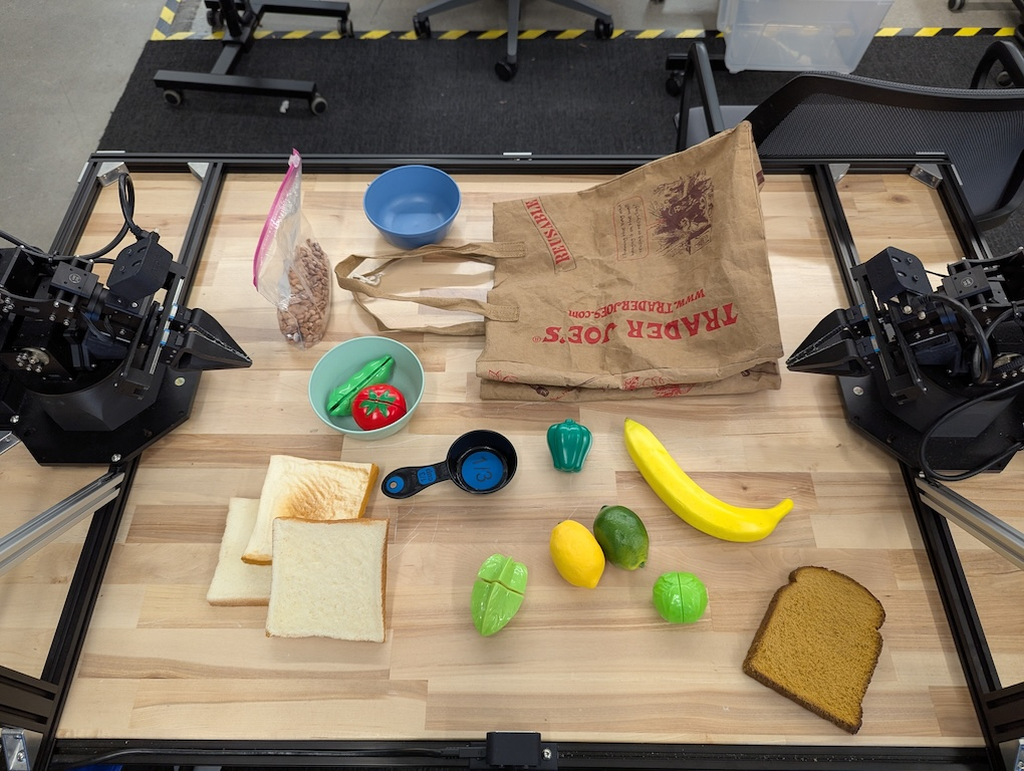

In [26]:
img = get_image_resized("aloha-arms-table.png")

prompt = textwrap.dedent("""\
    Point to no more than 10 items in the image. The label returned should be an
    identifying name for the object detected.

    The answer should follow the JSON format:
    [{"point": <point>, "label": <label1>}, ...]

    The points are in [y, x] format normalized to 0-1000.""")

start_time = time.time()
json_output = call_gemini_robotics_er(img, prompt)

print(f"\nTotal processing time: {(time.time() - start_time):.4f} seconds")
IPython.display.HTML(generate_point_html(img, json_output))

### Pointing to Defined Objects

It is also possible to provide a list of objects you'd like to find, and the model will limit its results to those objects.

```json
[
  {"point": [756, 321], "label": "bread"},
  {"point": [721, 239], "label": "bread"},
  {"point": [656, 299], "label": "bread"},
  {"point": [836, 792], "label": "bread"},
  {"point": [754, 482], "label": "starfruit"},
  {"point": [595, 650], "label": "banana"}
]
```

Total processing time: 6.0989 seconds



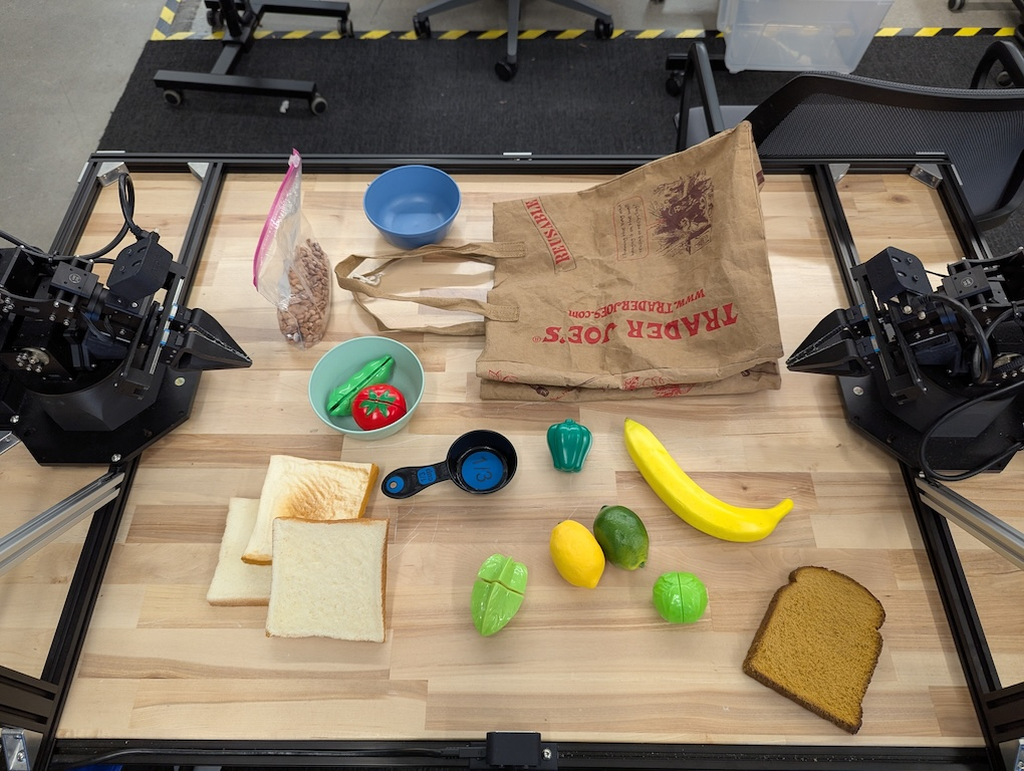

In [12]:
img = get_image_resized("aloha-arms-table.png")

queries = [
    "bread",
    "starfruit",
    "banana",
]

prompt = textwrap.dedent(f"""\
Get all points matching the following objects: {', '.join(queries)}. The label
returned should be an identifying name for the object detected.

The answer should follow the JSON format:
[{{"point": <point>, "label": <label1>}}, ...]

The points are in [y, x] format normalized to 0-1000.
""")

start_time = time.time()
json_output = call_gemini_robotics_er(img, prompt)

points_data = []
try:
  data = json.loads(json_output)
  points_data.extend(data)
except json.JSONDecodeError:
  print("Warning: Invalid JSON response. Skipping.")

print(f"\nTotal processing time: {(time.time() - start_time):.4f} seconds")
IPython.display.HTML(generate_point_html(img, json.dumps(points_data)))

### Point to all instances of an object based on more abstract description (e.g. "fruit")

Sometimes you may not know the exact item that will be in an environment, but you know the category. You can request that the model find objects of that category for you to then use to make more decisions

```json
[
  {"point": [530, 362], "label": "tomato"},
  {"point": [582, 556], "label": "bell pepper"},
  {"point": [595, 660], "label": "banana"},
  {"point": [706, 563], "label": "lemon"},
  {"point": [696, 608], "label": "lime"},
  {"point": [774, 662], "label": "green apple"}
]
```

Total processing time: 24.2349 seconds



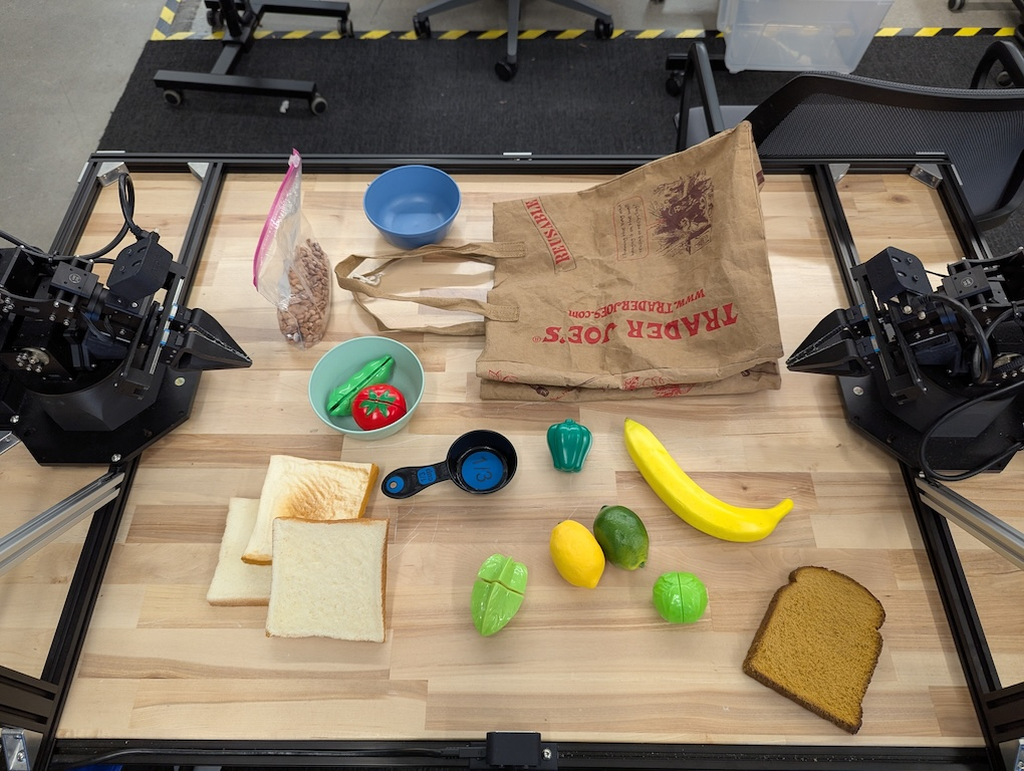

In [13]:
points_data = []
img = get_image_resized("aloha-arms-table.png")

prompt = textwrap.dedent(f"""\
        Get all points for fruit. The label returned should be an identifying
        name for the object detected.

        The answer should follow the json format:
        [{{"point": <point>, "label": <label1>}}, ...]

        The points are in [y, x] format normalized to 0-1000.""")

start_time = time.time()
json_output = call_gemini_robotics_er(img, prompt)

try:
  data = json.loads(json_output)
  points_data.extend(data)
except json.JSONDecodeError:
  print(f"Warning: Invalid JSON response, skipping.")

print(f"\nTotal processing time: {(time.time() - start_time):.4f} seconds")
IPython.display.HTML(generate_point_html(img, json.dumps(points_data)))

### Point to all instances of an object

```json
[
  {"point": [518, 528], "label": "game board slot"},
  {"point": [518, 606], "label": "game board slot"},
  {"point": [518, 684], "label": "game board slot"},
  {"point": [610, 528], "label": "game board slot"},
  {"point": [610, 606], "label": "game board slot"},
  {"point": [610, 684], "label": "game board slot"},
  {"point": [702, 528], "label": "game board slot"},
  {"point": [702, 606], "label": "game board slot"},
  {"point": [702, 684], "label": "game board slot"}
]
```
```json
[
  {"point": [550, 420], "label": "X game piece"},
  {"point": [648, 336], "label": "X game piece"},
  {"point": [461, 787], "label": "X game piece"},
  {"point": [549, 839], "label": "X game piece"}
]
```

Total processing time: 18.5365 seconds



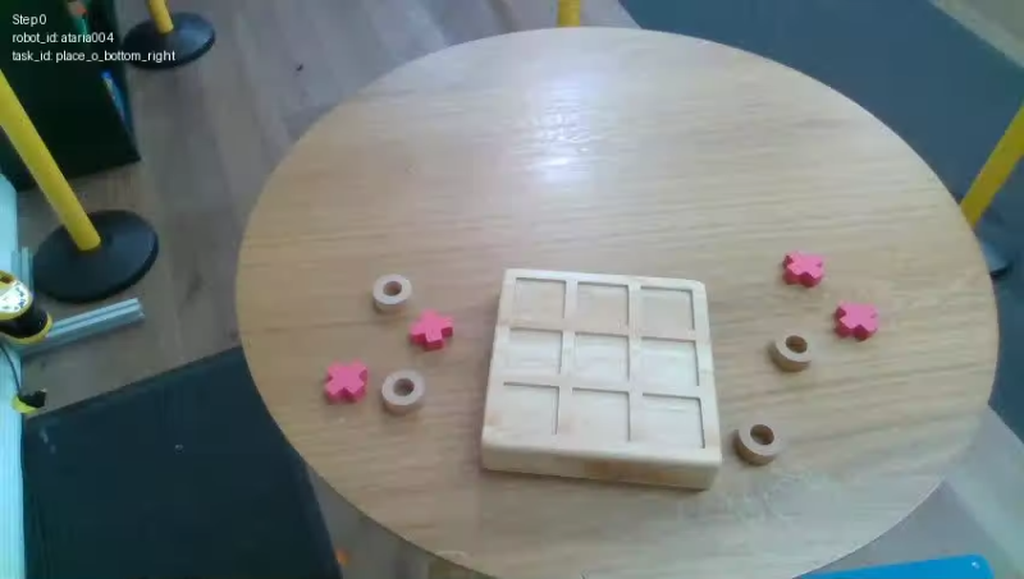

In [14]:
points_data = []
img = get_image_resized("gameboard.png")

queries = [
    "game board slot",
    "X game piece",
]

start_time = time.time()
for obj in queries:
  prompt = textwrap.dedent(f"""\
      Get all points matching {obj}. The label returned should be an identifying
      name for the object detected.

      The answer should follow the JSON format:
      [{{"point": <point>, "label": <label1>}}, ...]

      The points are in [y, x] format normalized to 0-1000.""")
  json_output = call_gemini_robotics_er(img, prompt)

  try:
    data = json.loads(json_output)
    points_data.extend(data)
  except json.JSONDecodeError:
    print(f"Warning: Invalid JSON response for {obj}. Skipping.")
    continue

print(f"\nTotal processing time: {(time.time() - start_time):.4f} seconds")
IPython.display.HTML(generate_point_html(img, json.dumps(points_data)))

```json
[
  {"point": [703, 608], "label": "lime"}
]
```
```json
[
  {"point": [602, 678], "label": "banana"}
]
```
```json
[
  {"point": [277, 401], "label": "rim of the light blue bowl"}
]
```
```json
[
  {"point": [392, 403], "label": "handles of the paper bag"}
]
```
```json
[
  {"point": [569, 708], "label": "the stem of the banana"}
]
```
```json
[
  {"point": [287, 427], "label": "rim"}
]
```
```json
[
  {"point": [602, 502], "label": "rim"}
]
```
```json
[
  {"point": [607, 408], "label": "handle of the measuring cup"}
]
```
```json
[
  {"point": [744, 488], "label": "starfruit"}
]
```
```json
[
  {"point": [521, 368], "label": "tomato of the bowl"}
]
```

Total processing time: 9.3546 seconds



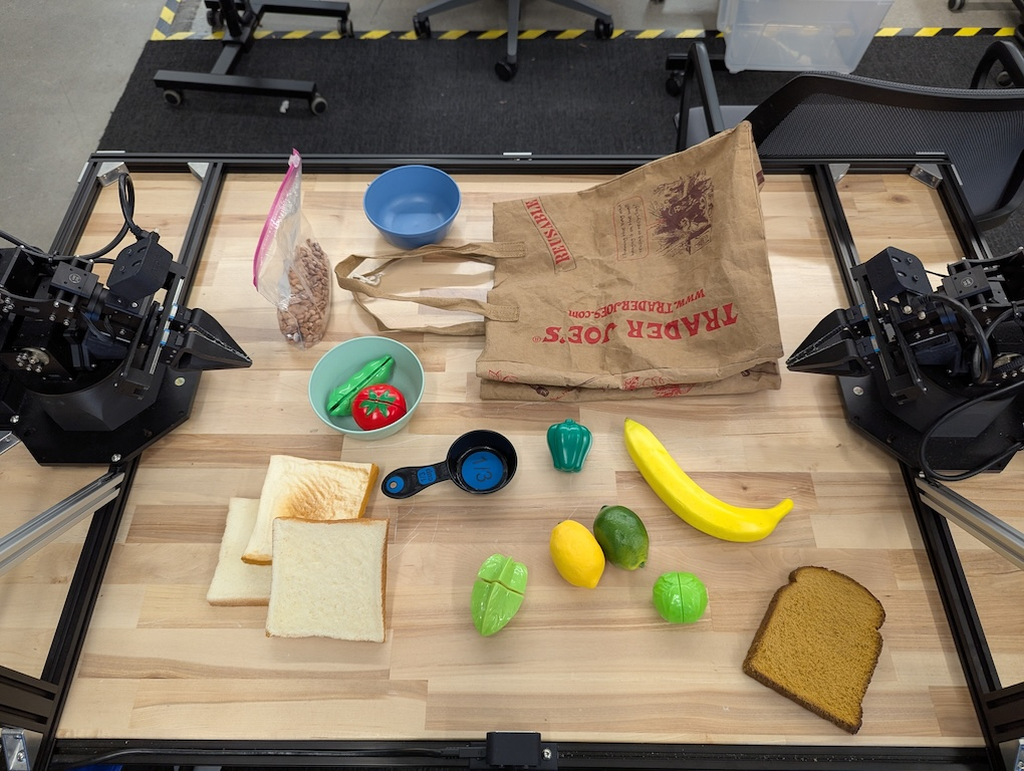

In [16]:
import concurrent.futures

img = get_image_resized("aloha-arms-table.png")
points_data = []

queries = [
    ("paper bag", "handles"),
    ("banana", "the stem"),
    ("banana", "center"),
    ("starfruit", "center"),
    ("lime", "center"),
    ("light blue bowl", "rim"),
    ("dark blue bowl", "rim"),
    ("measuring cup", "rim"),
    ("measuring cup", "handle"),
    ("bowl", "tomato"),
]

def process_query(obj, part):
  POINT_PROMPT_TEMPLATE = textwrap.dedent("""\
    Point to the $part of the $object in the image. Return the answer as a
    JSON list of a dictionary with keys 'point' and 'label'. Only return one
    point for this request.""")
  prompt = POINT_PROMPT_TEMPLATE.replace("$object", obj).replace("$part", part)
  json_output = call_gemini_robotics_er(img, prompt)
  try:
    data = json.loads(json_output)
    return data
  except json.JSONDecodeError:
    print(f"Warning: Invalid JSON response for {obj}, {part}. Skipping.")
    return []

start_time = time.time()
with concurrent.futures.ThreadPoolExecutor() as executor:
  results = executor.map(
      lambda query: process_query(query[0], query[1]), queries
  )

for result in results:
  points_data.extend(result)

print(f"\nTotal processing time: {(time.time() - start_time):.4f} seconds")
IPython.display.HTML(generate_point_html(img, json.dumps(points_data)))

### Pointing to Defined Objects in a GIF

In this example you can provide a list of objets you want to track along with their state, then send a gif or video file to Gemini to see what those object states are at set intervals.

Successfully loaded GIF: aloha-pen.gif
Extracted 160 frames from the GIF.
Processing frame 1/160...
  Successfully parsed 3 points for frame 1.
Processing frame 16/160...
  Successfully parsed 3 points for frame 16.
Processing frame 31/160...
  Successfully parsed 4 points for frame 31.
Processing frame 46/160...
  Successfully parsed 3 points for frame 46.
Processing frame 61/160...
  Successfully parsed 3 points for frame 61.
Processing frame 76/160...
  Successfully parsed 4 points for frame 76.
Processing frame 91/160...
  Successfully parsed 3 points for frame 91.
Processing frame 106/160...
  Successfully parsed 4 points for frame 106.
Processing frame 121/160...
  Successfully parsed 6 points for frame 121.
Processing frame 136/160...
  Successfully parsed 4 points for frame 136.
Processing frame 151/160...
  Successfully parsed 2 points for frame 151.
Collected point data for 11 analyzed frames.
Populated point data for 160 total frames.
Processed and drew points on 160 frames.

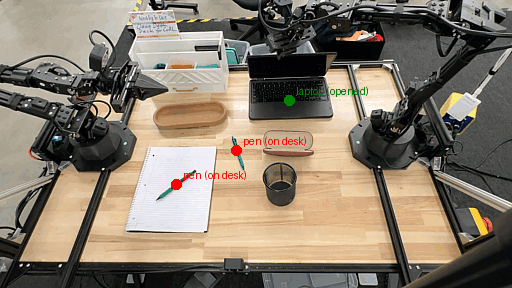

Displayed annotated GIF: /tmp/annotated_aloha_pen.gif


In [17]:
gif_path = "aloha-pen.gif"
try:
  gif = Image.open(gif_path)
  print(f"Successfully loaded GIF: {gif_path}")
except FileNotFoundError:
  print(f"Error: GIF file not found at {gif_path}")
  raise

frames = extract_frames(gif)

# Define the objects to query
queries = [
    "pen (on desk)",
    "pen (in robot hand)",
    "laptop (opened)",
    "laptop (closed)",
]

prompt = textwrap.dedent(f"""\
Point to the following objects in the provided image: {", ".join(queries)}.

The answer should follow the JSON format:
[{{"point": <point>, "label": <label1>}}, ...]

The points are in [y, x] format normalized to 0-1000.

If no objects are found, return an empty JSON list [].""")


# Send every 15th frame as a separate request for the sake of time
analyzed_frames_data = []
frame_step = 15

for i in range(0, len(frames), frame_step):
  frame_index = i
  frame = frames[frame_index]
  print(f"Processing frame {frame_index+1}/{len(frames)}...")

  try:
    image_response = client.models.generate_content(
        model=MODEL_ID,
        contents=[frame, prompt],
        config=types.GenerateContentConfig(
            temperature=0.5,
            thinking_config=types.ThinkingConfig(thinking_budget=0),
        ),
    )

    try:
      json_output = parse_json(image_response.text)
      frame_points = json.loads(json_output)
      analyzed_frames_data.append(frame_points)
      print(
          f"  Successfully parsed {len(frame_points)} points for frame"
          f" {frame_index+1}."
      )
    except json.JSONDecodeError as e:
      print(
          f"  Error decoding JSON for frame {frame_index+1}: {e}. Appending"
          " empty list."
      )
      analyzed_frames_data.append([])
    except Exception as e:
      print(
          "  An unexpected error occurred processing frame"
          f" {frame_index+1} response: {e}. Appending empty list."
      )
      analyzed_frames_data.append([])

  except Exception as e:
    print(
        f"  Error generating content for frame {frame_index+1}: {e}. Appending"
        " empty list."
    )
    analyzed_frames_data.append([])


print(f"Collected point data for {len(analyzed_frames_data)} analyzed frames.")

points_data_all_frames = populate_points_for_all_frames(
    len(frames), frame_step, analyzed_frames_data
)
print(f"Populated point data for {len(points_data_all_frames)} total frames.")


modified_frames = overlay_points_on_frames(frames, points_data_all_frames)
display_gif(modified_frames)